In [5]:
import os
BASE_DIR = "\\notebooks\\experiments"
if os.getcwd().endswith(BASE_DIR):
    os.chdir(os.path.abspath(os.path.join(os.getcwd(), '..', '..')))

In [36]:
from src.models.model_handler import save_model, load_model, get_class_def_from_notebook
from src.models.testing_utils import evaluate_continuous, predict_continuous
from src.data.preprocessing import generate_classification_tensors
from src.data.DatasetGenerator import DatasetGenerator
from src.models.training_utils import train_model
from sklearn.preprocessing import LabelEncoder
from src.utils.helpers import load_param

from torch.utils.data import TensorDataset, DataLoader
import torch.nn.functional as F
import torch.nn as nn
import pandas as pd
import torch

In [7]:
dg = DatasetGenerator(num_particules=10000)

generators = [
    ("rw", dg.generate_RandomWalk),
    ("bm", dg.generate_BrownianMotion),
    ("ctrw", dg.generate_ContinuousTimeRandomWalk),
    ("fbm", dg.generate_FractionalBrownianMotion),
    ("lw", dg.generate_LevyWalks),
    ("attm", dg.generate_AnnealedTransitTimeModel),
    ("sbm", dg.generate_ScaledBrownianMotion),
]

dataframes = []
for prefix, func in generators:
    df = func(random_params=True, num_passos=200)
    dataframes.append(df)

data = pd.concat(dataframes, ignore_index=True)
data

c:\Users\jmass\Documents\GitHub\TFG_GEINF\env\Lib\site-packages\fbm\fbm.py:171: UserWarning: Combination of increments n and Hurst value H invalid for Davies-Harte method. Reverting to Hosking method. Occurs when n is small and Hurst is close to 1. 
  warnings.warn(


,coords,num_steps,trajectory_type,attributes
0,"[[0.0, -1.0, -1.0, -2.0, -2.0, -3.0, -2.0, -3....",200,Random Walk,{'movement_type': 'nonstop'}
1,"[[0.0, -1.0, 0.0, 0.0, -1.0, 0.0, 0.0, -1.0, -...",200,Random Walk,{'movement_type': 'nonstop'}
2,"[[0.0, 0.0, -1.0, -1.0, -2.0, -2.0, -2.0, -2.0...",200,Random Walk,{'movement_type': 'chill_stop'}
3,"[[0.0, -1.0, -1.0, -1.0, -2.0, -1.0, -1.0, 0.0...",200,Random Walk,{'movement_type': 'nonstop'}
4,"[[0.0, 0.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 1.0,...",200,Random Walk,{'movement_type': 'hard_stop'}
...,...,...,...,...
69995,"[[-0.14691720627589958, 0.43124908550964647, 1...",200,Scaled Brownian Motion,{'beta': 0.8897584753824421}
69996,"[[1.399813187474228, 3.0227720403988005, 3.407...",200,Scaled Brownian Motion,{'beta': 1.8259709124369345}
69997,"[[-0.028410683561225503, 0.7213766566762265, 0...",200,Scaled Brownian Motion,{'beta': 0.7815582963662835}
69998,"[[2.4433144600476444, 5.191072271259405, 6.575...",200,Scaled Brownian Motion,{'beta': 1.8051357258823104}


In [8]:
le = LabelEncoder()
X_tensor, y_tensor = generate_classification_tensors(data, 'trajectory_type', le)

In [9]:
# Aconseguir X_train, X_val, X_test, y_train, y_val i y_test
n, train_end, val_end = len(X_tensor), int(0.7 * len(X_tensor)), int(0.85 * len(X_tensor))
X_train, X_val, X_test = X_tensor[:train_end], X_tensor[train_end:val_end], X_tensor[val_end:]
y_train, y_val, y_test = y_tensor[:train_end], y_tensor[train_end:val_end], y_tensor[val_end:]

In [10]:
# Muntem els Data_loaders
learning_batch_size = 32
try_batch_size = 1

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=learning_batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=try_batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=try_batch_size, shuffle=True)

In [ ]:
# 6. Definir la arquitectura CNN
class TrajectoryTypeClassifier(nn.Module):
    def __init__(self, input_channels, num_classes):
        super().__init__()
        self.first_conv = nn.Conv1d(input_channels, 32, kernel_size=3, padding=1)
        self.conv1_32 = nn.Conv1d(32, 32, kernel_size=3, padding=1)
        self.conv2_32 = nn.Conv1d(32, 32, kernel_size=3, padding=1)
        self.conv_32_64 = nn.Conv1d(32, 64, kernel_size=3, padding=1)
        self.conv1_64 = nn.Conv1d(64, 64, kernel_size=3, padding=1)
        self.conv2_64 = nn.Conv1d(64, 64, kernel_size=3, padding=1)
        self.conv_64_128 = nn.Conv1d(64, 128, kernel_size=3, padding=1)
        self.conv1_128 = nn.Conv1d(128, 128, kernel_size=3, padding=1)
        self.conv2_128 = nn.Conv1d(128, 128, kernel_size=3, padding=1)
        self.max_pool = nn.MaxPool1d(2)
        self.avg_pool = nn.AdaptiveAvgPool2d((1, 4))
        self.fc1 = nn.Linear(4, 256)
        self.fc2 = nn.Linear(256, num_classes)

    
    def forward(self, data):
        a_resnet = self.first_conv(data)
        a = self.conv1_32(a_resnet)
        a = self.conv2_32(a)
        a = a + a_resnet
        a = self.max_pool(a)
        b_resnet = self.conv_32_64(a)
        b = self.conv1_64(b_resnet)
        b = self.conv2_64(b)
        b = b + b_resnet
        b = self.max_pool(b)
        c_resnet = self.conv_64_128(b)
        c = self.conv1_128(c_resnet)
        c = self.conv2_128(c)
        c = c + c_resnet
        c = self.avg_pool(c)
        c = c.view(c.size(0), -1)  # Aplanar la salida
        c = F.relu(self.fc1(c))
        c = self.fc2(c)
        return c

In [52]:
import json

with open("notebooks/experiments/trainingTrajectoryTypeClassifier.ipynb", "r", encoding="utf-8") as f:
    nb = json.load(f)
model_source = nb["cells"][6]["source"]
if isinstance(model_source, list):
    model_source = "".join(model_source)

print(model_source)

# 6. Definir la arquitectura CNN
class TrajectoryTypeClassifier(nn.Module):
    def __init__(self, input_channels, num_classes):
        super().__init__()
        self.first_conv = nn.Conv1d(input_channels, 32, kernel_size=3, padding=1)
        self.conv1_32 = nn.Conv1d(32, 32, kernel_size=3, padding=1)
        self.conv2_32 = nn.Conv1d(32, 32, kernel_size=3, padding=1)
        self.conv_32_64 = nn.Conv1d(32, 64, kernel_size=3, padding=1)
        self.conv1_64 = nn.Conv1d(64, 64, kernel_size=3, padding=1)
        self.conv2_64 = nn.Conv1d(64, 64, kernel_size=3, padding=1)
        self.conv_64_128 = nn.Conv1d(64, 128, kernel_size=3, padding=1)
        self.conv1_128 = nn.Conv1d(128, 128, kernel_size=3, padding=1)
        self.conv2_128 = nn.Conv1d(128, 128, kernel_size=3, padding=1)
        self.max_pool = nn.MaxPool1d(2)
        self.avg_pool = nn.AdaptiveAvgPool2d((1, 4))
        self.fc1 = nn.Linear(4, 256)
        self.fc2 = nn.Linear(256, num_classes)

    
    def forward(self, d

In [ ]:
input_channels = 2

# Inicialitzem el model d'aquesta manera per poder després guardar facilment els paràmetres
model_params = {
    "input_channels": input_channels,
    "num_classes": len(le.classes_)
}

model = TrajectoryTypeClassifier(**model_params)

In [12]:
# optimizer=torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-3)
# scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
#     optimizer, 
#     mode='min',  # Minimizar val_loss
#     factor=0.2,  # Reduce LR a 20% del actual
#     patience=3,  # Espera 3 epochs sin mejora
#     verbose=True  # Muestra mensajes
# )


# best_model = train_regressor_model(
#     model=model,
#     criterion=nn.CrossEntropyLoss(),
#     optimizer=optimizer,
#     num_epochs=15,
#     train_loader=train_loader,
#     val_loader=val_loader,
#     scheduler=scheduler,
#     print_epoch=True,
#     patience=5
# )

# 8. Configurar entrenamiento
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 9. Entrenar el modelo
num_epochs = 15

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    
    for inputs, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_loader):.4f}")

Epoch [1/15], Loss: 1.4372
Epoch [2/15], Loss: 1.2511
Epoch [3/15], Loss: 0.7591
Epoch [4/15], Loss: 0.6103
Epoch [5/15], Loss: 0.5726
Epoch [6/15], Loss: 0.5350
Epoch [7/15], Loss: 0.5308
Epoch [8/15], Loss: 0.5056
Epoch [9/15], Loss: 0.5167
Epoch [10/15], Loss: 0.4751
Epoch [11/15], Loss: 0.4556
Epoch [12/15], Loss: 0.4316
Epoch [13/15], Loss: 0.4162
Epoch [14/15], Loss: 0.3970
Epoch [15/15], Loss: 0.9962


In [162]:
with torch.no_grad():
    test_outputs = model(X_test)
    _, predicted = torch.max(test_outputs, 1)  # Índices de las clases predichas
    true_labels = torch.argmax(y_test, dim=1)  # Convertir one-hot a índices
    accuracy = (predicted == true_labels).float().mean()
    print(f'Test Accuracy: {accuracy.item():.4f}')

Test Accuracy: 0.8326


In [172]:
import random

# Seleccionar el primer ejemplo de X_test y añadir una dimensión batch
random_value = random.randint(1, 500)
# print("Valor random entre 1 y 500:", random_value)
first_example = X_test[random_value].unsqueeze(0)  # shape: (1, 2, 200)

# Pasar por el modelo
model.eval()
with torch.no_grad():
    output = model(first_example)
    predicted_class = torch.argmax(output, dim=1).item()

# Mostrar el resultado
print("Predicción (índice de clase):", predicted_class)
print("Clase predicha:", le.inverse_transform([predicted_class])[0])
# Mostrar la clase real
true_class = torch.argmax(y_test[random_value]).item()
print("Clase real:", le.inverse_transform([true_class])[0])

Predicción (índice de clase): 4
Clase predicha: Lévy Walk
Clase real: Lévy Walk


In [11]:
evaluate_continuous(best_model, X_test, y_test)

Test MSE: 0.0189


0.018906662240624428

In [12]:
predict_continuous(best_model, X_test, y_test, num_samples=10)

Predicciones:
Ejemplo 1: Predicho = 0.6406972408294678, Real = [0.54004186]
Ejemplo 2: Predicho = 0.4589676260948181, Real = [0.52591753]
Ejemplo 3: Predicho = 0.3457889258861542, Real = [0.17001842]
Ejemplo 4: Predicho = 0.7203972935676575, Real = [0.77847546]
Ejemplo 5: Predicho = 0.27398133277893066, Real = [0.2676552]
Ejemplo 6: Predicho = 0.5036356449127197, Real = [0.36038285]
Ejemplo 7: Predicho = 0.6786308884620667, Real = [0.8246553]
Ejemplo 8: Predicho = 0.6253182888031006, Real = [0.70867896]
Ejemplo 9: Predicho = 0.9011772871017456, Real = [0.963228]
Ejemplo 10: Predicho = 0.7878854274749756, Real = [0.96272326]


In [13]:
SAVE_PATH = "../../../models/trained_models/"

In [53]:
import torch
import dill
import os
import inspect
import torch.nn as nn
import torch.nn.functional as F

def save_model(model_instance, model_source, attributes, input_channels, model_name=None, path=None, le=None):
    if model_name is None:
        model_name = model_instance.__class__.__name__
    filename = f"{model_name}.pth"
    if path is not None:
        os.makedirs(path, exist_ok=True)
        save_path = os.path.join(path, filename)
    else:
        save_path = filename
    torch.save({
        "model_name": model_name,
        "model_type": "type_classifier",
        "model_source": model_source,
        "state_dict": model_instance.state_dict(),
        "attributes": attributes,
        "input_channels": input_channels
        , **({"le": le} if le is not None else {})
    }, save_path, pickle_module=dill)


save_model(model_instance=model,
           model_source=model_source,
           attributes=model_params,
           input_channels=input_channels,
           path=load_param("path", "model"),
           le=le
           )

In [240]:
import torch
import dill
import os
import inspect
import torch.nn as nn
import torch.nn.functional as F

def load_model(model_path):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    checkpoint = torch.load(model_path, map_location=device, pickle_module=dill)
    
    # Ejecutar el código fuente para recrear la clase
    exec(checkpoint["model_source"], globals())  # La clase se define en el scope global
    
    # Instanciar el modelo con sus argumentos originales
    model_class = globals()[checkpoint["model_source"].split("class ")[1].split("(")[0].strip()]
    model = model_class(**checkpoint["attributes"])
    model.load_state_dict(checkpoint["state_dict"])
    model.to(device)
    model.eval()
    if checkpoint["le"] is not None:
        return model, checkpoint["le"]
    return model

prova_carrega_model, le=load_model(
    load_param("path", "model") +
    "TrajectoryTypeClassifier.pth"
)

In [246]:
import random

# Seleccionar el primer ejemplo de X_test y añadir una dimensión batch
random_value = random.randint(1, 500)
# print("Valor random entre 1 y 500:", random_value)
first_example = X_test[random_value].unsqueeze(0)  # shape: (1, 2, 200)

# Pasar por el modelo
prova_carrega_model.eval()
with torch.no_grad():
    output = prova_carrega_model(first_example)
    predicted_class = torch.argmax(output, dim=1).item()

# Mostrar el resultado
print("Predicción (índice de clase):", predicted_class)
print("Clase predicha:", le.inverse_transform([predicted_class])[0])
# Mostrar la clase real
true_class = torch.argmax(y_test[random_value]).item()
print("Clase real:", le.inverse_transform([true_class])[0])

Predicción (índice de clase): 2
Clase predicha: CTRW
Clase real: CTRW


torch.Size([1, 2, 20000]) torch.Size([1, 7])
tensor([[-46.9665,  -5.3648, -11.0596,   0.6810,  -8.4167, -61.0463, -16.9360]])
Fractional Brownian Motion


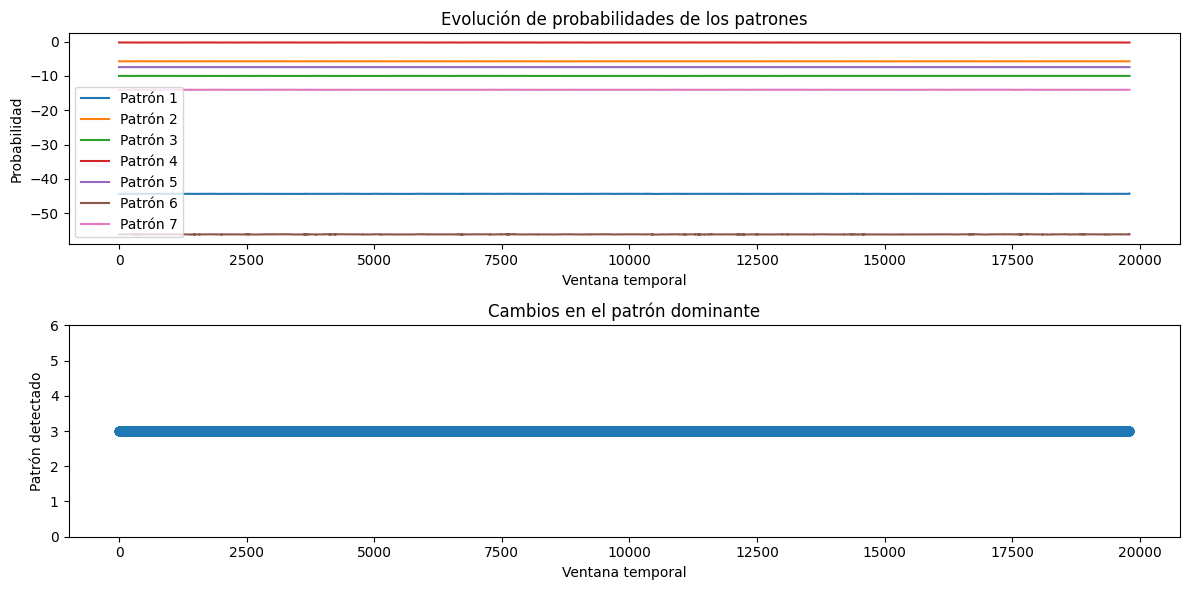

In [ ]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

traj = DatasetGenerator(num_particules=1).generate_FractionalBrownianMotion(num_passos=20000, random_params=True)
X_tensor, y_tensor = generate_classification_tensors(traj, 'trajectory_type', LabelEncoder())
print(X_tensor.shape, y_tensor.shape)
with torch.no_grad():
    out = model(X_tensor)
    print(out)
    predicted_class = torch.argmax(out, dim=1).item()
    print(le.inverse_transform([predicted_class])[0])

# Usamos unfold en la dimensión 2 (la de longitud n)
X_unfolded = X_tensor.unfold(dimension=2, size=200, step=1)  # [1, 2, 91, 200]

# Reordenamos para que cada ventana sea un tensor independiente
X_windows = X_unfolded.permute(2, 0, 1, 3)  # [91, 1, 2, 10]

# Convertimos a una lista de tensores de shape [1, 2, 10]
X_list = [x for x in X_windows]  # lista de 91 tensores

X_adjusted = []

for window in X_list:
    # Extraemos el punto de inicio [1, 2, 1] → expandimos para broadcasting
    start = window[:, :, 0].unsqueeze(-1)
    # Restamos el punto inicial a toda la ventana
    adjusted = window - start
    X_adjusted.append(adjusted)

prova_carrega_model.eval()
outputs = []
values = []
with torch.no_grad():
    for x in X_adjusted:
        out = prova_carrega_model(x)
        predicted_class = torch.argmax(out, dim=1).item()
        array = out.numpy()[0]
        outputs.append(np.array(array))
        values.append(le.inverse_transform([predicted_class])[0])

outputs = np.array(outputs)
if outputs.size > 0:
    plt.figure(figsize=(12, 6))
    
    # Gráfico de probabilidades
    plt.subplot(2, 1, 1)
    for i in range(7):
        plt.plot(outputs[:, i], label=f'Patrón {i+1}')
    plt.title('Evolución de probabilidades de los patrones')
    plt.xlabel('Ventana temporal')
    plt.ylabel('Probabilidad')
    plt.legend()
    
    # Gráfico de patrón dominante
    plt.subplot(2, 1, 2)
    patron_dominante = np.argmax(outputs, axis=1)
    plt.plot(patron_dominante, 'o-')
    plt.title('Cambios en el patrón dominante')
    plt.xlabel('Ventana temporal')
    plt.ylabel('Patrón detectado')
    plt.yticks(range(7))
    
    plt.tight_layout()
    plt.show()

In [290]:
from collections import Counter
import numpy as np

# Obtener el índice de la clase dominante para cada ventana
patron_dominante = np.argmax(outputs, axis=1)
# Convertir los índices a nombres de clase usando el label encoder
labels = le.inverse_transform(patron_dominante)
print("patron_dominante:", patron_dominante)
print(Counter(labels).most_common(7))
# Imprimir la leyenda de los índices de clase
for i in range(len(le.classes_)):
    print(f"{i}: {le.inverse_transform([i])[0]}")

patron_dominante: [1 1 1 ... 4 4 4]
[('Brownian Motion', 13088), ('Lévy Walk', 4340), ('Scaled Brownian Motion', 2373)]
0: ATTM
1: Brownian Motion
2: CTRW
3: Fractional Brownian Motion
4: Lévy Walk
5: Random Walk
6: Scaled Brownian Motion


In [295]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

# Generar dos trayectorias de tipos diferentes y concatenarlas
dg = DatasetGenerator(num_particules=1)
traj1 = dg.generate_FractionalBrownianMotion(num_passos=10000, random_params=True)
traj2 = dg.generate_RandomWalk(num_passos=10000, random_params=True)

# Concatenar las trayectorias
traj_concat = traj1.copy()
# Obtener el último valor de traj1
last_coords_traj1 = np.array(traj1.iloc[0]["coords"])
last_point = last_coords_traj1[:, -1]

# Obtener los valores de traj2 y sumarle el último punto de traj1
coords_traj2 = np.array(traj2.iloc[0]["coords"])
coords_traj2_shifted = coords_traj2 + last_point[:, None]

# Concatenar las coordenadas
coords_concat = np.concatenate([last_coords_traj1, coords_traj2_shifted], axis=1)

# Actualizar el DataFrame concatenado
traj_concat.at[0, "coords"] = coords_concat.tolist()
traj_concat.at[0, "num_steps"] = coords_concat.shape[1]
traj_concat.at[0, "trajectory_type"] = traj1.iloc[0]["trajectory_type"] + "+" + traj2.iloc[0]["trajectory_type"]

traj = traj_concat

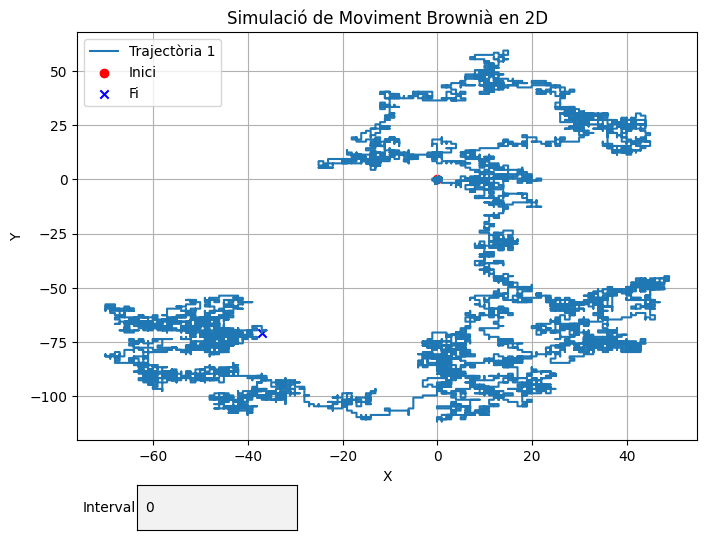

In [294]:
from src.analysis.DataAnalyzer import DataAnalyzer
DataAnalyzer = DataAnalyzer(traj)
DataAnalyzer.mostrar_trajectories()

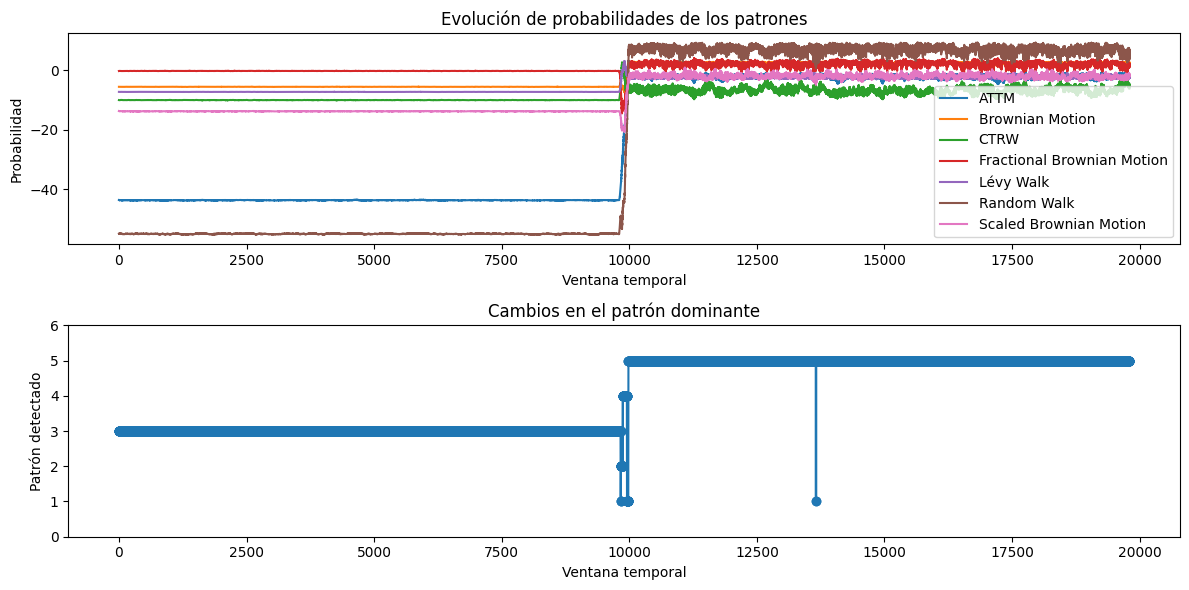

In [ ]:

X_tensor, y_tensor = generate_classification_tensors(traj, 'trajectory_type', LabelEncoder())
print(X_tensor.shape, y_tensor.shape)
with torch.no_grad():
    out = model(X_tensor)
    print(out)
    predicted_class = torch.argmax(out, dim=1).item()
    print(le.inverse_transform([predicted_class])[0])

# Usamos unfold en la dimensión 2 (la de longitud n)
X_unfolded = X_tensor.unfold(dimension=2, size=200, step=1)  # [1, 2, 91, 200]

# Reordenamos para que cada ventana sea un tensor independiente
X_windows = X_unfolded.permute(2, 0, 1, 3)  # [91, 1, 2, 10]

# Convertimos a una lista de tensores de shape [1, 2, 10]
X_list = [x for x in X_windows]  # lista de 91 tensores

X_adjusted = []

for window in X_list:
    # Extraemos el punto de inicio [1, 2, 1] → expandimos para broadcasting
    start = window[:, :, 0].unsqueeze(-1)
    # Restamos el punto inicial a toda la ventana
    adjusted = window - start
    X_adjusted.append(adjusted)

prova_carrega_model.eval()
outputs = []
values = []
with torch.no_grad():
    for x in X_adjusted:
        out = prova_carrega_model(x)
        predicted_class = torch.argmax(out, dim=1).item()
        array = out.numpy()[0]
        outputs.append(np.array(array))
        values.append(le.inverse_transform([predicted_class])[0])

outputs = np.array(outputs)
if outputs.size > 0:
    plt.figure(figsize=(12, 6))
    
    # Gráfico de probabilidades
    plt.subplot(2, 1, 1)
    for i in range(7):
        plt.plot(outputs[:, i], label=f'{le.inverse_transform([i])[0]}')
    plt.title('Evolución de probabilidades de los patrones')
    plt.xlabel('Ventana temporal')
    plt.ylabel('Probabilidad')
    plt.legend()
    
    # Gráfico de patrón dominante
    plt.subplot(2, 1, 2)
    patron_dominante = np.argmax(outputs, axis=1)
    plt.plot(patron_dominante, 'o-')
    plt.title('Cambios en el patrón dominante')
    plt.xlabel('Ventana temporal')
    plt.ylabel('Patrón detectado')
    plt.yticks(range(7))
    
    plt.tight_layout()
    plt.show()

In [ ]:
with torch.no_grad():
    test_outputs = model(X_tensor)
    _, predicted = torch.max(test_outputs, 1)  # Índices de las clases predichas
    true_labels = torch.argmax(y_tensor, dim=1)  # Convertir one-hot a índices
    accuracy = (predicted == true_labels).float().mean()
    print(f'Test Accuracy: {accuracy.item():.4f}')

Test Accuracy: 0.0610


In [203]:
X_test.shape, y_test.shape

(torch.Size([10500, 2, 200]), torch.Size([10500, 7]))

In [204]:
X_tensor.shape, y_tensor.shape

(torch.Size([1000, 2, 10]), torch.Size([1000, 7]))